In [2]:
# Import packages for data manipulation
import pandas as pd
import numpy as np

# Import packages for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import packages for data preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.utils import resample

# Import packages for data modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
df = pd.read_csv("data/Raw/tiktok_dataset.csv")

In [4]:
df.isnull().sum()

#                             0
claim_status                298
video_id                      0
video_duration_sec            0
video_transcription_text    298
verified_status               0
author_ban_status             0
video_view_count            298
video_like_count            298
video_share_count           298
video_download_count        298
video_comment_count         298
dtype: int64

In [5]:
df.dropna(axis=0, inplace=True)

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.columns.to_list()

['#',
 'claim_status',
 'video_id',
 'video_duration_sec',
 'video_transcription_text',
 'verified_status',
 'author_ban_status',
 'video_view_count',
 'video_like_count',
 'video_share_count',
 'video_download_count',
 'video_comment_count']

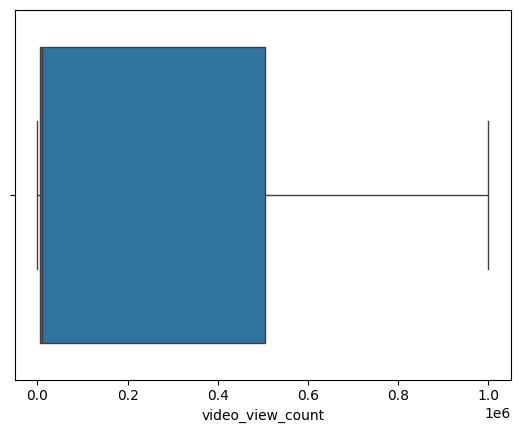

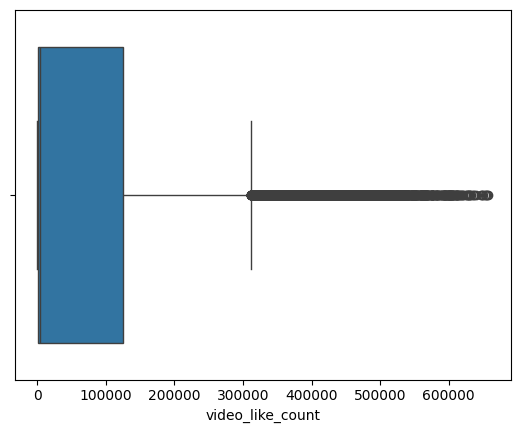

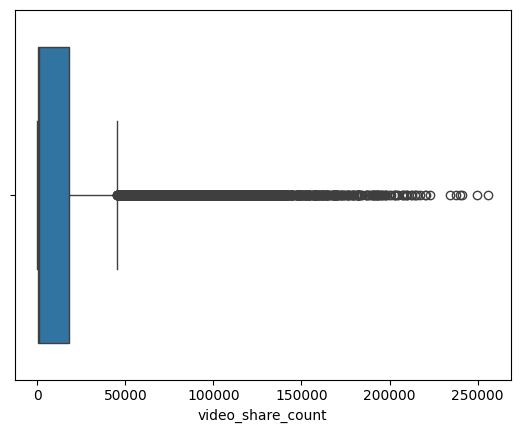

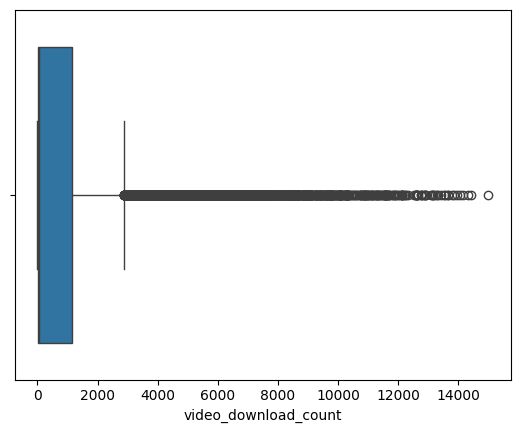

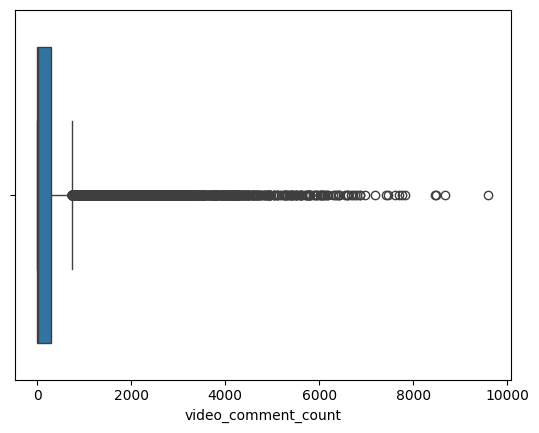

In [8]:
count_cols = [
    "video_view_count",
    "video_like_count",
    "video_share_count",
    "video_download_count",
    "video_comment_count",
]

for col in count_cols:
    sns.boxplot(x=df[col])
    plt.show()


<Axes: xlabel='video_like_count'>

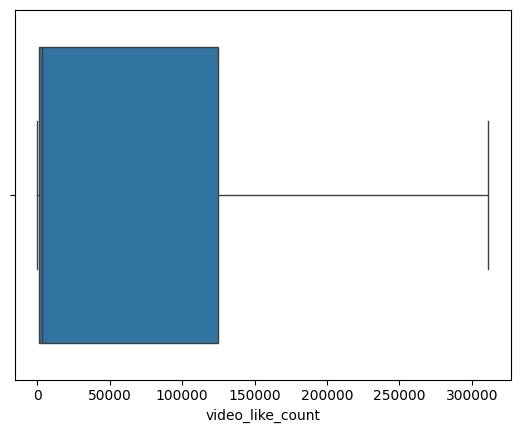

In [9]:
# like count
q1 = df.video_like_count.quantile(0.25)
q3 = df.video_like_count.quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

df.loc[df.video_like_count > upper_limit, "video_like_count"] = upper_limit
sns.boxplot(x=df.video_like_count)

<Axes: xlabel='video_comment_count'>

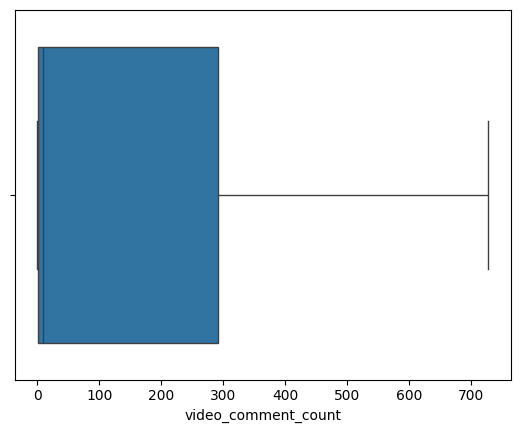

In [10]:
# comment count
q1 = df.video_comment_count.quantile(0.25)
q3 = df.video_comment_count.quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

df.loc[df.video_comment_count > upper_limit, "video_comment_count"] = upper_limit
sns.boxplot(x=df.video_comment_count)

Checking target class balance

In [11]:
df.verified_status.value_counts(normalize=True)

verified_status
not verified    0.93712
verified        0.06288
Name: proportion, dtype: float64

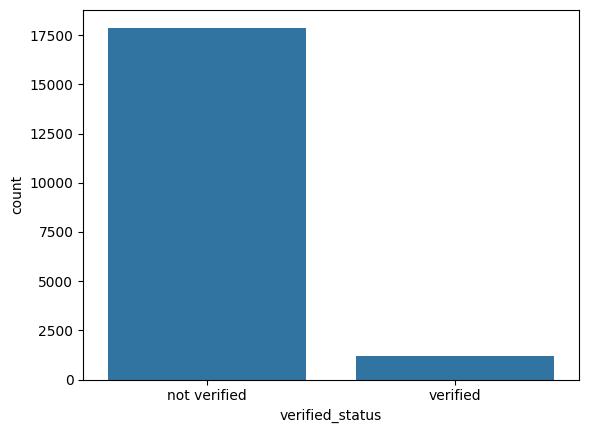

In [12]:
sns.countplot(x=df.verified_status);

93% not verified, 7% verified

Resampling data to balance target class

In [13]:
# Use resampling to create class balance in the outcome variable, if needed

# Identify df points from majority and minority classes
df_majority = df[df["verified_status"] == "not verified"]
df_minority = df[df["verified_status"] == "verified"]

# Upsample the minority class (which is "verified")
df_minority_upsampled = resample(
    df_minority,
    replace=True,  # to sample with replacement
    n_samples=len(df_majority),  # to match majority class
    random_state=0,
)  # to create reproducible results

# Combine majority class with upsampled minority class
df_upsampled = pd.concat([df_majority, df_minority_upsampled]).reset_index(drop=True)

# Display new class counts
df_upsampled["verified_status"].value_counts()

verified_status
not verified    17884
verified        17884
Name: count, dtype: int64

In [14]:
df_upsampled["t_length"] = df_upsampled["video_transcription_text"].str.len()


df_upsampled[["verified_status", "t_length"]].groupby(["verified_status"]).mean()

,t_length
verified_status,
not verified,89.401141
verified,84.569559


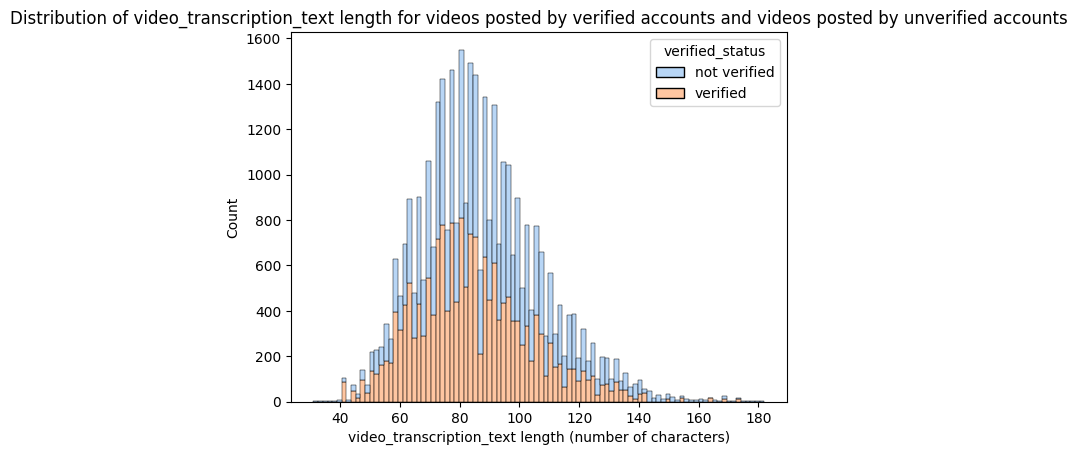

In [15]:
# Visualize the distribution of `video_transcription_text` length for videos posted by verified accounts and videos posted by unverified accounts
# Create two histograms in one plot
sns.histplot(
    data=df_upsampled,
    multiple="stack",
    x="t_length",
    kde=False,
    palette="pastel",
    hue="verified_status",
    legend=True,
)
plt.xlabel("video_transcription_text length (number of characters)")
plt.ylabel("Count")
plt.title(
    "Distribution of video_transcription_text length for videos posted by verified accounts and videos posted by unverified accounts"
)
plt.show()

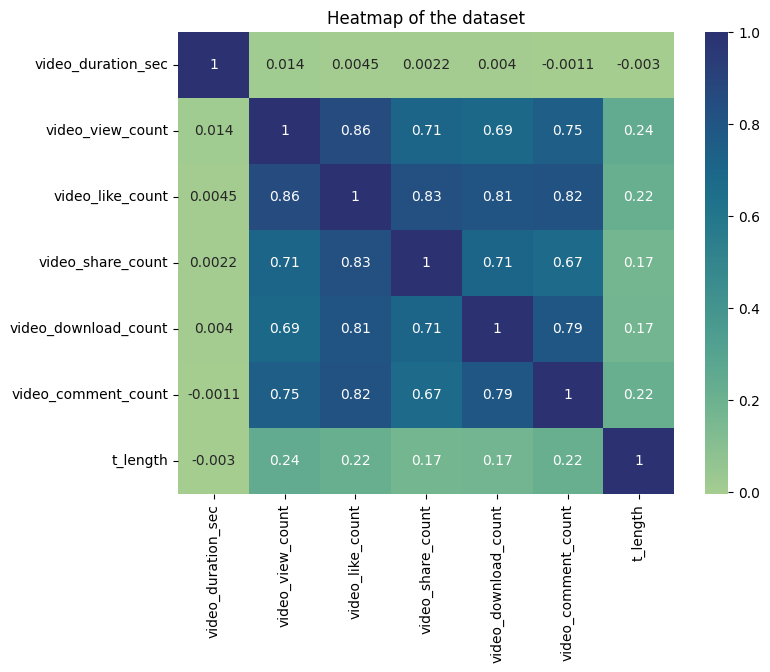

In [16]:
corr = df_upsampled.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(
    df_upsampled[
        [
            "video_duration_sec",
            "claim_status",
            "author_ban_status",
            "video_view_count",
            "video_like_count",
            "video_share_count",
            "video_download_count",
            "video_comment_count",
            "t_length",
        ]
    ].corr(numeric_only=True),
    annot=True,
    cmap="crest",
)
plt.title("Heatmap of the dataset")
plt.show()

The above heatmap shows that the following pair of variables are strongly correlated: video_view_count and video_like_count (0.86 correlation coefficient).

One of the model assumptions for logistic regression is no severe multicollinearity among the features. To build a logistic regression model that meets this assumption, you could exclude video_like_count. And among the variables that quantify video metrics, you could keep video_view_count, video_share_count, video_download_count, and video_comment_count as features.

In [17]:
y = df_upsampled["verified_status"]
X = df_upsampled[
    [
        "video_duration_sec",
        "claim_status",
        "author_ban_status",
        "video_view_count",
        "video_share_count",
        "video_download_count",
        "video_comment_count",
    ]
]


Train Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

In [19]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((26826, 7), (8942, 7), (26826,), (8942,))

Encoding variables

In [20]:
X_train.dtypes

video_duration_sec        int64
claim_status             object
author_ban_status        object
video_view_count        float64
video_share_count       float64
video_download_count    float64
video_comment_count     float64
dtype: object

In [ ]:
X_to_encode = X_train[["claim_status", "author_ban_status"]]
X_to_encode.head()

,claim_status,author_ban_status
33058,opinion,active
20491,opinion,active
25583,opinion,active
18474,opinion,active
27312,opinion,active


In [ ]:
X_encoder = OneHotEncoder(drop="first", sparse_output=False)

In [41]:
X_train_encoded = X_encoder.fit_transform(X_to_encode)

In [ ]:
X_train_encoded_df = pd.DataFrame(
    data=X_train_encoded, columns=X_encoder.get_feature_names_out()
)


In [ ]:
X_train_final = pd.concat(
    [
        X_train.drop(columns=["claim_status", "author_ban_status"]).reset_index(
            drop=True
        ),
        X_train_encoded_df,
    ],
    axis=1,
)

# Display first few rows
X_train_final.head()

,video_duration_sec,video_view_count,video_share_count,video_download_count,video_comment_count,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,33,2252.0,23.0,4.0,0.0,1.0,0.0,0.0
1,52,6664.0,550.0,53.0,2.0,1.0,0.0,0.0
2,37,6327.0,257.0,3.0,0.0,1.0,0.0,0.0
3,57,1702.0,28.0,0.0,0.0,1.0,0.0,0.0
4,21,3842.0,101.0,1.0,0.0,1.0,0.0,0.0


In [46]:
y_train.unique()

array(['verified', 'not verified'], dtype=object)

In [ ]:
y_train_final = y_train.replace({"verified": 1, "not verified": 0}).astype(int)

C:\Users\Sarvamm\AppData\Local\Temp\ipykernel_9252\2687741402.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_train_final = y_train.replace( {'verified':1 , 'not verified':0} ).astype(int)


Model Building

In [ ]:
# Construct a logistic regression model and fit it to the training set
model = LogisticRegression(random_state=0, max_iter=800).fit(
    X_train_final, y_train_final
)

In [52]:
# Select the testing features that needs to be encoded
X_test_to_encode = X_test[["claim_status", "author_ban_status"]]

In [53]:
X_test_encoded = X_encoder.transform(X_test_to_encode)

In [ ]:
X_test_encoded_df = pd.DataFrame(
    data=X_test_encoded, columns=X_encoder.get_feature_names_out()
)


In [ ]:
X_test_final = pd.concat(
    [
        X_test.drop(columns=["claim_status", "author_ban_status"]).reset_index(
            drop=True
        ),
        X_test_encoded_df,
    ],
    axis=1,
)

# Display first few rows
X_test_final.head()

,video_duration_sec,video_view_count,video_share_count,video_download_count,video_comment_count,claim_status_opinion,author_ban_status_banned,author_ban_status_under review
0,41,2118.0,57.0,5.0,2.0,1.0,0.0,0.0
1,27,5701.0,157.0,1.0,0.0,1.0,0.0,0.0
2,31,449767.0,75385.0,5956.0,728.5,0.0,0.0,0.0
3,19,792813.0,56597.0,5146.0,728.5,0.0,0.0,0.0
4,54,2044.0,68.0,19.0,2.0,1.0,0.0,0.0


In [57]:
yh = model.predict(X_test_final)

In [59]:
y_test.unique()

array(['verified', 'not verified'], dtype=object)

In [60]:
y_test_final = y_test.replace({"verified": 1, "not verified": 0}).astype(int)

C:\Users\Sarvamm\AppData\Local\Temp\ipykernel_9252\1661061367.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_test_final = y_test.replace({"verified": 1, "not verified": 0}).astype(int)


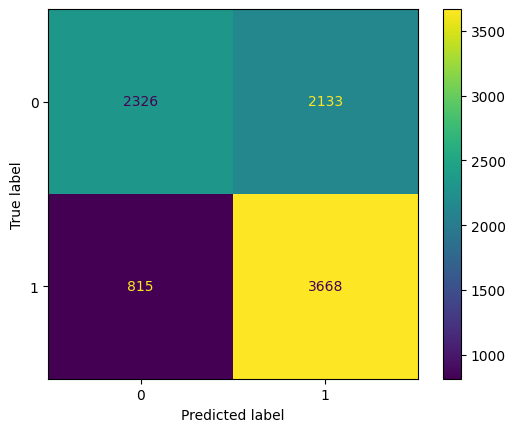

In [61]:
cm = confusion_matrix(y_test_final, yh, labels=model.classes_)

ConfusionMatrixDisplay(cm, display_labels=model.classes_).plot();

In [63]:
# Create classification report for logistic regression model
target_labels = ["verified", "not verified"]
print(classification_report(y_test_final, yh, target_names=target_labels))

              precision    recall  f1-score   support

    verified       0.74      0.52      0.61      4459
not verified       0.63      0.82      0.71      4483

    accuracy                           0.67      8942
   macro avg       0.69      0.67      0.66      8942
weighted avg       0.69      0.67      0.66      8942



In [ ]:
# Get the feature names from the model and the model coefficients (which represent log-odds ratios)
# Place into a DataFrame for readability
pd.DataFrame(
    data={"Feature Name": model.feature_names_in_, "Model Coefficient": model.coef_[0]}
)

,Feature Name,Model Coefficient
0,video_duration_sec,-2.454196e-03
1,video_view_count,-1.690365e-07
2,video_share_count,4.825919e-06
3,video_download_count,-8.108600e-05
4,video_comment_count,4.483293e-04
5,claim_status_opinion,1.702486e+00
6,author_ban_status_banned,-4.483992e-01
7,author_ban_status_under review,-9.867372e-02
